# Radar tracks, HRRR-AK grid, and DEM coverage

## Goal

Investigate where **radar observations and gridded forcing overlap**, as a first step toward designing point snow-model simulations.

1. Inspect the downloaded WY2021 HRRR-AK NetCDF and choose an example timestamp.
2. Compare the stored HRRR grid footprint, radar tracks, and six-tile DEM bounding box.
3. Check both geometric overlap and valid HRRR data at radar locations.
4. Group radar locations by stored HRRR grid cell.
5. Select and map one actual radar point per eligible cell as a candidate model site.

**Kernel:** JIF snow modeling (`jif_snow_modeling`).

> **Time matching is not established:** the radar CSV identifies 2021 but has no acquisition timestamp column. The editable **1 May 2021, 12:00 UTC** setting below is an illustrative snapshot, not a confirmed survey date.

> **Spatial interpretation:** this HRRR file is already reprojected to UTM at approximately 3 km spacing. We examine its stored cells without terrain downscaling. These cell IDs do not establish a one-to-one mapping to the original HRRR projection/grid.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
import rasterio
from rasterio.windows import Window
from rasterio.warp import transform_bounds
from pyproj import CRS, Transformer
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from IPython.display import display
import cartopy.crs as ccrs
import cartopy.feature as cfeature

HRRR_PATH = Path('/hdd/snow_hydrology/hrrrak/icefield_domain/netcdf/hrrrak_merged_grib_f567_WY2021_utm.nc')
RADAR_PATH = Path('/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv')
DEM_PATH = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic/jif_tiles_utm8n_20m.tif')
PIT_PATH = Path('/hdd/snow_hydrology/JIF_radar/jif_snow_pit_sites_2021.csv')
RADAR_EPSG = 32608  # Provisional WGS 84 / UTM 8N assumption; datum not specified in radar readme.
TARGET_TIME_UTC = pd.Timestamp('2021-05-01T12:00:00')  # Example only; update when survey dates are known.
TIME_TOLERANCE = pd.Timedelta('1h')
SAVE_OUTPUTS = True
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'radar' / '02_radar_hrrrak_dem_coverage.ipynb').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Launch from the repository root or radar/.')
FIGURE_DIR = REPO_ROOT / 'radar' / 'figures'
DATA_DIR = REPO_ROOT / 'radar' / 'data'
if SAVE_OUTPUTS:
    FIGURE_DIR.mkdir(exist_ok=True)
    DATA_DIR.mkdir(exist_ok=True)
for path in [HRRR_PATH, RADAR_PATH, DEM_PATH, PIT_PATH]:
    if not path.is_file():
        raise FileNotFoundError(path)
print('Python:', sys.executable)
print('Radar datum assumption:', CRS.from_epsg(RADAR_EPSG).name)

Python: /home/cassie/programs/miniforge3/envs/jif_snow_modeling/bin/python
Radar datum assumption: WGS 84 / UTM zone 8N


## 1. Inspect HRRR coverage, time, and variable metadata

- Open the NetCDF lazily and load **only one timestamp of temperature and orography**.
- Read the projection from the file rather than assigning one by assumption.
- Report actual timestamp coverage, spacing, forecast steps, and any time/valid-time mismatch.
- Use per-variable units; dataset-level attributes describe one variable and are not valid metadata for every field.
- Sort the displayed snapshot coordinates west-to-east and south-to-north. Later cell indices use that sorted snapshot grid, not the original NetCDF row order.

In [2]:
with xr.open_dataset(HRRR_PATH, decode_coords='all') as ds:
    print(ds)
    grid_crs = CRS.from_user_input(ds.rio.crs)
    if not grid_crs.is_projected or grid_crs.to_epsg() != 32608:
        raise ValueError(f'Inspect this workflow before using an unexpected grid CRS: {grid_crs}')
    times = pd.DatetimeIndex(ds['time'].values)
    if not times.is_unique or not times.is_monotonic_increasing:
        raise ValueError('Time coordinate must be unique and increasing.')
    print('Grid CRS:', grid_crs.to_string())
    print('Stored time coverage:', times.min(), 'to', times.max(), '(interpreted as UTC)')
    print('Number of timestamps:', len(times))
    print('Time increments:', pd.Series(times[1:] - times[:-1]).value_counts().to_dict())
    if 'valid_time' in ds:
        if not np.array_equal(ds['valid_time'].values, ds['time'].values):
            raise ValueError('time differs from valid_time; resolve time semantics before selecting a snapshot.')
        print('time equals valid_time for every timestamp.')
    if 'step' in ds:
        print('Stored forecast lead times:', np.unique(ds['step'].values).astype('timedelta64[h]'))
    variables = pd.DataFrame([{'variable': name, 'units': v.attrs.get('units', ''),
                               'description': v.attrs.get('long_name', ''), 'dimensions': str(v.dims)}
                              for name, v in ds.data_vars.items()])
    display(variables)
    selected = times.get_indexer([TARGET_TIME_UTC], method='nearest', tolerance=TIME_TOLERANCE)[0]
    if selected < 0:
        raise ValueError('Requested time has no timestamp within TIME_TOLERANCE.')
    snapshot = ds[['temp', 'orog']].isel(time=selected).sortby('x').sortby('y').load()
    actual_time = pd.Timestamp(snapshot['time'].values)
print('Requested example time:', TARGET_TIME_UTC, 'UTC')
print('Selected stored time:', actual_time, 'UTC')
if snapshot['temp'].attrs.get('units') != 'K' or snapshot['orog'].attrs.get('units') != 'm':
    raise ValueError('Confirm temperature/orography units before plotting.')
temp_c = snapshot['temp'].values - 273.15
orography = snapshot['orog'].values
x, y = snapshot.x.values, snapshot.y.values
print('Stored grid shape (y, x):', temp_c.shape)
print('Finite temperature cells:', int(np.isfinite(temp_c).sum()), '/', temp_c.size)

<xarray.Dataset> Size: 4GB
Dimensions:       (time: 8760, y: 59, x: 31)
Coordinates:
    valid_time    (time) datetime64[ns] 70kB ...
    step          (time) timedelta64[ns] 70kB ...
  * time          (time) datetime64[ns] 70kB 2020-10-01T05:00:00 ... 2021-10-...
  * y             (y) float64 472B 6.618e+06 6.615e+06 ... 6.449e+06 6.446e+06
  * x             (x) float64 248B 4.98e+05 5.009e+05 ... 5.842e+05 5.871e+05
    spatial_ref   int32 4B ...
Data variables: (12/28)
    gust          (time, y, x) float64 128MB ...
    pressure      (time, y, x) float64 128MB ...
    orog          (time, y, x) float64 128MB ...
    temp_surface  (time, y, x) float64 128MB ...
    swe           (time, y, x) float64 128MB ...
    snowdepth     (time, y, x) float64 128MB ...
    ...            ...
    suswrf        (time, y, x) float64 128MB ...
    sulwrf        (time, y, x) float64 128MB ...
    wind          (time, y, x) float64 128MB ...
    wind_dir      (time, y, x) float64 128MB ...
    veg   

,variable,units,description,dimensions
0,gust,m s**-1,Wind speed (gust),"('time', 'y', 'x')"
1,pressure,Pa,Surface pressure,"('time', 'y', 'x')"
2,orog,m,Orography,"('time', 'y', 'x')"
3,temp_surface,K,Temperature,"('time', 'y', 'x')"
4,swe,kg m**-2,Water equivalent of accumulated snow depth (de...,"('time', 'y', 'x')"
5,snowdepth,m,Snow depth,"('time', 'y', 'x')"
6,temp,K,2 metre temperature,"('time', 'y', 'x')"
7,2sh,kg kg**-1,2 metre specific humidity,"('time', 'y', 'x')"
8,2d,K,2 metre dewpoint temperature,"('time', 'y', 'x')"
9,rh,%,2 metre relative humidity,"('time', 'y', 'x')"


Requested example time: 2021-05-01 12:00:00 UTC
Selected stored time: 2021-05-01 12:00:00 UTC
Stored grid shape (y, x): (59, 31)
Finite temperature cells: 1787 / 1829


## 2. Build cell edges and locate the datasets

- Derive cell boundaries from adjacent **grid centres**, including half-cell edges at the perimeter.
- Require regular spacing; do not assume the stored spacing is exactly 3,000 m.
- Transform radar coordinates and the DEM bounds into the HRRR file's CRS.
- The DEM bounding box is a coverage outline, not proof that every DEM pixel is valid. Check the DEM mask at radar locations separately.

**Existing point-model sites:** MLD4 (58.85892°N, 134.15728°W) and TKG4 (58.63447°N, 134.23708°W), from their site forcing notebooks. They are transformed from WGS 84 longitude/latitude into the stored HRRR grid CRS and shown at their actual coordinates.

In [3]:
def cell_edges(centres):
    centres = np.asarray(centres, dtype=float)
    diffs = np.diff(centres)
    if len(centres) < 2 or not np.all(diffs > 0) or not np.allclose(diffs, diffs[0], rtol=1e-6):
        raise ValueError('Expected a regularly spaced increasing coordinate axis.')
    return np.r_[centres[0] - diffs[0] / 2, (centres[:-1] + centres[1:]) / 2,
                 centres[-1] + diffs[-1] / 2]

x_edges, y_edges = cell_edges(x), cell_edges(y)
hrrr_bounds = (x_edges[0], y_edges[0], x_edges[-1], y_edges[-1])
print(f'Stored cell spacing: {np.diff(x)[0]:.3f} m × {np.diff(y)[0]:.3f} m')
radar = pd.read_csv(RADAR_PATH, encoding='utf-8-sig')
finite_coordinates = np.isfinite(radar[['east', 'north']]).all(axis=1)
points = radar.loc[finite_coordinates].copy()
if points.empty:
    raise ValueError('No finite radar coordinates.')
points['source_csv_row_0based'] = points.index
transform_radar = Transformer.from_crs(RADAR_EPSG, grid_crs, always_xy=True)
points['grid_x'], points['grid_y'] = transform_radar.transform(points.east.to_numpy(), points.north.to_numpy())
with rasterio.open(DEM_PATH) as dem:
    dem_bounds = transform_bounds(dem.crs, grid_crs, *dem.bounds, densify_pts=101)
    dem_native_bounds, dem_crs = dem.bounds, dem.crs
print('HRRR outer cell-edge bounds:', hrrr_bounds)
print('Six-tile DEM raster bounds:', dem_bounds)
print(f'{len(points):,} finite radar coordinates; {(~finite_coordinates).sum():,} excluded coordinate rows.')

# Site coordinates from the WY2020-WY2025 SMET forcing notebooks in sites/.
# Plot actual site coordinates, not their nearest HRRR grid centres.
reference_sites = pd.DataFrame([
    {'site': 'MLD4', 'latitude': 58.85892, 'longitude': -134.15728, 'colour': '#ffd700',
     'coordinate_source': 'sites/mld4/2_create_snowpack_smet_forcing_hrrrak_mld4_WY2020-WY2025.ipynb'},
    {'site': 'TKG4', 'latitude': 58.63447, 'longitude': -134.23708, 'colour': '#00c8b4',
     'coordinate_source': 'sites/tkg4/2_create_snowpack_smet_forcing_hrrrak_tkg4_WY2020-WY2025.ipynb'},
])
site_transform = Transformer.from_crs('EPSG:4326', grid_crs, always_xy=True)
reference_sites['grid_x'], reference_sites['grid_y'] = site_transform.transform(
    reference_sites.longitude.to_numpy(), reference_sites.latitude.to_numpy())
display(reference_sites[['site', 'latitude', 'longitude', 'grid_x', 'grid_y', 'coordinate_source']])
reference_site_handles = [Line2D([], [], marker='*', linestyle='none', markersize=12,
                                  markerfacecolor=site.colour, markeredgecolor='black',
                                  label=f'{site.site} existing model site')
                          for site in reference_sites.itertuples()]

def add_reference_sites(ax):
    for site in reference_sites.itertuples():
        ax.scatter(site.grid_x, site.grid_y, transform=ccrs.epsg(grid_crs.to_epsg()),
                    marker='*', s=240, facecolor=site.colour, edgecolor='black',
                    linewidth=1, zorder=10)
        # All map axes use the same projected coordinates as grid_crs.
        ax.annotate(site.site, xy=(site.grid_x, site.grid_y), xytext=(9, 9),
                     textcoords='offset points', fontsize=9, fontweight='bold', zorder=11,
                     bbox={'facecolor': 'white', 'edgecolor': '#555555', 'alpha': 0.9, 'pad': 2})


Stored cell spacing: 2972.994 m × 2972.994 m


HRRR outer cell-edge bounds: (np.float64(496468.3178110652), np.float64(6444250.622521915), np.float64(588631.1196165059), np.float64(6619657.245312914))
Six-tile DEM raster bounds: (499900.0, 6433960.0, 595980.0, 6577740.0)
119,218 finite radar coordinates; 0 excluded coordinate rows.


,site,latitude,longitude,grid_x,grid_y,coordinate_source
0,MLD4,58.85892,-134.15728,548613.301054,6.524649e+06,sites/mld4/2_create_snowpack_smet_forcing_hrrr...
1,TKG4,58.63447,-134.23708,544294.565344,6.499603e+06,sites/tkg4/2_create_snowpack_smet_forcing_hrrr...


## 3. Quantify overlap and match radar points to stored grid cells

### Coverage checks

- **Inside HRRR bounds:** the coordinate falls inside the outer cell edges.
- **Valid temperature/orography:** its assigned HRRR cell has finite data at the selected example time.
- **Inside DEM bounds:** the coordinate falls within the six-tile raster bounding box.
- **Valid DEM elevation:** the nearest DEM pixel is valid at that radar location.

Cell assignment uses containing cells on the regular projected grid, equivalent to nearest-centre selection except at shared boundaries. Boundary ties go east/north; outside points remain unassigned. **No interpolation or elevation correction is performed.**

In [4]:
gx, gy = points.grid_x.to_numpy(), points.grid_y.to_numpy()
col = np.searchsorted(x_edges, gx, side='right') - 1
row = np.searchsorted(y_edges, gy, side='right') - 1
inside_hrrr = (col >= 0) & (col < len(x)) & (row >= 0) & (row < len(y))
points['inside_hrrr_bounds'] = inside_hrrr
points['grid_col_west_to_east'] = pd.array(np.where(inside_hrrr, col, np.nan), dtype='Int64')
points['grid_row_south_to_north'] = pd.array(np.where(inside_hrrr, row, np.nan), dtype='Int64')
points['hrrr_temperature_C'] = np.nan
points['hrrr_orography_m'] = np.nan
points.loc[inside_hrrr, 'hrrr_temperature_C'] = temp_c[row[inside_hrrr], col[inside_hrrr]]
points.loc[inside_hrrr, 'hrrr_orography_m'] = orography[row[inside_hrrr], col[inside_hrrr]]
points['hrrr_example_time_UTC'] = str(actual_time)
points['radar_crs_assumption'] = f'EPSG:{RADAR_EPSG}'

# Blockwise sampling avoids reading the entire full-resolution DEM.
points['dem_elevation_m'] = np.nan
with rasterio.open(DEM_PATH) as dem:
    tx, ty = Transformer.from_crs(grid_crs, dem.crs, always_xy=True).transform(gx, gy)
    dr, dc = rasterio.transform.rowcol(dem.transform, tx, ty)
    dr, dc = np.asarray(dr), np.asarray(dc)
    inside_dem = (dr >= 0) & (dr < dem.height) & (dc >= 0) & (dc < dem.width)
    ids = np.flatnonzero(inside_dem)
    groups = pd.DataFrame({'id': ids, 'br': dr[ids] // 512, 'bc': dc[ids] // 512})
    values = np.full(len(points), np.nan)
    for (br, bc), group in groups.groupby(['br', 'bc']):
        r0, c0 = int(br * 512), int(bc * 512)
        window = Window(c0, r0, min(512, dem.width - c0), min(512, dem.height - r0))
        data = dem.read(1, window=window, masked=True)
        ii = group.id.to_numpy()
        values[ii] = data[dr[ii] - r0, dc[ii] - c0].astype(float).filled(np.nan)
    points['dem_elevation_m'] = values
points['inside_dem_bounds'] = inside_dem
points['valid_hrrr_temperature'] = np.isfinite(points.hrrr_temperature_C)
points['valid_hrrr_orography'] = np.isfinite(points.hrrr_orography_m)
points['valid_dem_elevation'] = np.isfinite(points.dem_elevation_m)
checks = ['inside_hrrr_bounds', 'valid_hrrr_temperature', 'valid_hrrr_orography',
          'inside_dem_bounds', 'valid_dem_elevation']
coverage_summary = pd.DataFrame([{'check': name, 'radar_points': int(points[name].sum()),
                                  'percent': 100 * points[name].mean()} for name in checks])
display(coverage_summary)
print('Flags refer to the selected HRRR snapshot and the current DEM, not all times or every meteorological variable.')
if SAVE_OUTPUTS:
    coverage_summary.to_csv(DATA_DIR / 'radar_hrrrak_dem_coverage.csv', index=False)
    points.to_csv(DATA_DIR / 'radar_hrrrak_grid_assignments.csv', index=False)

,check,radar_points,percent
0,inside_hrrr_bounds,119218,100.0
1,valid_hrrr_temperature,119218,100.0
2,valid_hrrr_orography,119218,100.0
3,inside_dem_bounds,119218,100.0
4,valid_dem_elevation,119218,100.0


Flags refer to the selected HRRR snapshot and the current DEM, not all times or every meteorological variable.


## 4. Map the overlapping extents

### Figure panels

- **Regional:** HRRR temperature cells with the downloaded DEM bounding box and all radar tracks.
- **Radar close-up:** the same field and stored grid boundaries around the radar footprint.
- **Blue outline:** outer HRRR cell edges; **orange outline:** six-tile DEM raster bounding box.
- **Magenta tracks:** radar points; grey cells have missing temperature in the selected snapshot.

The temperature field supplies spatial context at an **illustrative** 2021 timestamp. It is not a radar-date match or a snow-model validation result. Basemap features come from Natural Earth via Cartopy (cached locally or downloaded on first use).

**Star markers:** gold **MLD4** and turquoise **TKG4** mark the existing model sites in every map panel. They are reference locations and do not alter the 55-cell candidate selection.

**2021 snow pits:** white-filled black circles show measured depths; a lime diamond marks **MG5**, whose 4.90 m depth is a **lower bound** (firn/ice not reached). Pit `east`/`north` are UTM Zone 8N with an unconfirmed horizontal datum: provisionally assume **WGS 84 / UTM 8N (EPSG:32608)**, exactly as for radar, and use the same transformer into the stored HRRR CRS. This is an assumption, not a verified datum identification.

**MG2 is excluded from both maps** because `quality_flags` identifies its suspicious northing (6,319,112 m). Its original easting/northing are retained without correction in the loaded data and exported review table. Both panels retain their original bounds; pits outside a panel are clipped. Labels use manual offsets and leader lines to separate nearby sites, including pit TKG4 from the existing TKG4 model site. Pit dates are archived dig dates; date/density-sampling flags remain visible below for comparison-site selection.


In [5]:
# Inspect quality flags before selecting any map locations. Keep source coordinates unchanged.
pits = pd.read_csv(PIT_PATH, encoding='utf-8-sig', parse_dates=['pit_date'])
pits['quality_flags'] = pits.quality_flags.fillna('')
pits['depth_is_lower_bound'] = pits.quality_flags.str.contains('depth_is_lower_bound', regex=False)
pits['excluded_from_map'] = ((pits.site_id == 'MG2') |
    pits.quality_flags.str.contains('northing_outside_study_area', regex=False))
pits['map_status'] = np.where(pits.excluded_from_map, 'Excluded: suspicious northing; original coordinates retained',
                              np.where(pits.depth_is_lower_bound, 'Lower-bound depth', 'Measured depth'))
pits['coordinate_assumption'] = f'EPSG:{RADAR_EPSG}; horizontal datum unconfirmed (same assumption as radar)'
# Use precisely the radar coordinate transformation, without editing east/north.
pits['grid_x'], pits['grid_y'] = transform_radar.transform(pits.east.to_numpy(), pits.north.to_numpy())
pit_summary = pits[['site_id', 'pit_date', 'snow_depth_m', 'quality_flags', 'map_status']].copy()
with pd.option_context('display.max_colwidth', None):
    display(pit_summary.style.format({'pit_date': lambda d: d.strftime('%Y-%m-%d'),
                                     'snow_depth_m': '{:.2f}'}).hide(axis='index'))
print('MG5: snow depth ≥ 4.90 m. MG2 excluded; original (east, north):',
      list(pits.loc[pits.site_id == 'MG2', ['east', 'north']].itertuples(index=False, name=None)))
if SAVE_OUTPUTS:
    pits.to_csv(DATA_DIR / 'snow_pit_sites_2021_review.csv', index=False, date_format='%Y-%m-%d')

pit_handles = [Line2D([], [], marker='o', linestyle='none', markersize=7,
                     markerfacecolor='white', markeredgecolor='black', label='2021 snow pits'),
               Line2D([], [], marker='D', linestyle='none', markersize=7,
                     markerfacecolor='#b5f542', markeredgecolor='black', label='MG5 pit: depth ≥ 4.90 m')]

def add_snow_pits(ax, bounds, regional=False):
    # Offsets in display points: fan out the close Lemon Creek cluster and separate TKG4 stars.
    offsets = {'G': (-30, -28), 'D': (12, -12), 'H': (20, 13),
               'TKG4': (14, -22), 'TKG3': (-35, 10), 'TKG2': (-34, 10),
               'DG1': (14, -8), 'TKG5': (12, -24), 'C161': (-35, -12),
               'MG1': (12, 9), 'MG5': (12, 9), 'VLG1': (-38, 9)}
    for pit in pits.loc[~pits.excluded_from_map].itertuples():
        if not (bounds[0] <= pit.grid_x <= bounds[2] and bounds[1] <= pit.grid_y <= bounds[3]):
            continue
        ax.scatter(pit.grid_x, pit.grid_y, transform=map_crs,
                   marker='D' if pit.depth_is_lower_bound else 'o', s=65,
                   facecolor='#b5f542' if pit.depth_is_lower_bound else 'white',
                   edgecolor='black', linewidth=1.2, zorder=12)
        offset = offsets.get(pit.site_id, (10, 10))
        ax.annotate(pit.site_id, (pit.grid_x, pit.grid_y), xytext=offset,
                    textcoords='offset points', fontsize=8, fontweight='bold', zorder=13,
                    annotation_clip=True,
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9, 'pad': 1.5},
                    arrowprops={'arrowstyle': '-', 'color': 'black', 'lw': 0.6})


site_id,pit_date,snow_depth_m,quality_flags,map_status
G,2021-06-30,4.10,,Measured depth
D,2021-06-27,5.30,,Measured depth
H,2021-06-30,5.10,density_sampled_2021-07-01_after_dig_date,Measured depth
TKG5,2021-07-12,3.33,archived_pit_date_differs_from_paper_table1_gt_date,Measured depth
TKG3,2021-07-09,3.78,archived_pit_date_differs_from_paper_table1_gt_date,Measured depth
TKG4,2021-07-07,3.78,archived_pit_date_differs_from_paper_table1_gt_date;density_sampled_2021-07-08_after_dig_date,Measured depth
TKG2,2021-07-15,3.60,,Measured depth
DG1,2021-07-10,3.15,,Measured depth
C161,2021-07-15,4.73,,Measured depth
MG1,2021-07-19,3.44,,Measured depth


MG5: snow depth ≥ 4.90 m. MG2 excluded; original (east, north): [(546507, 6319112)]


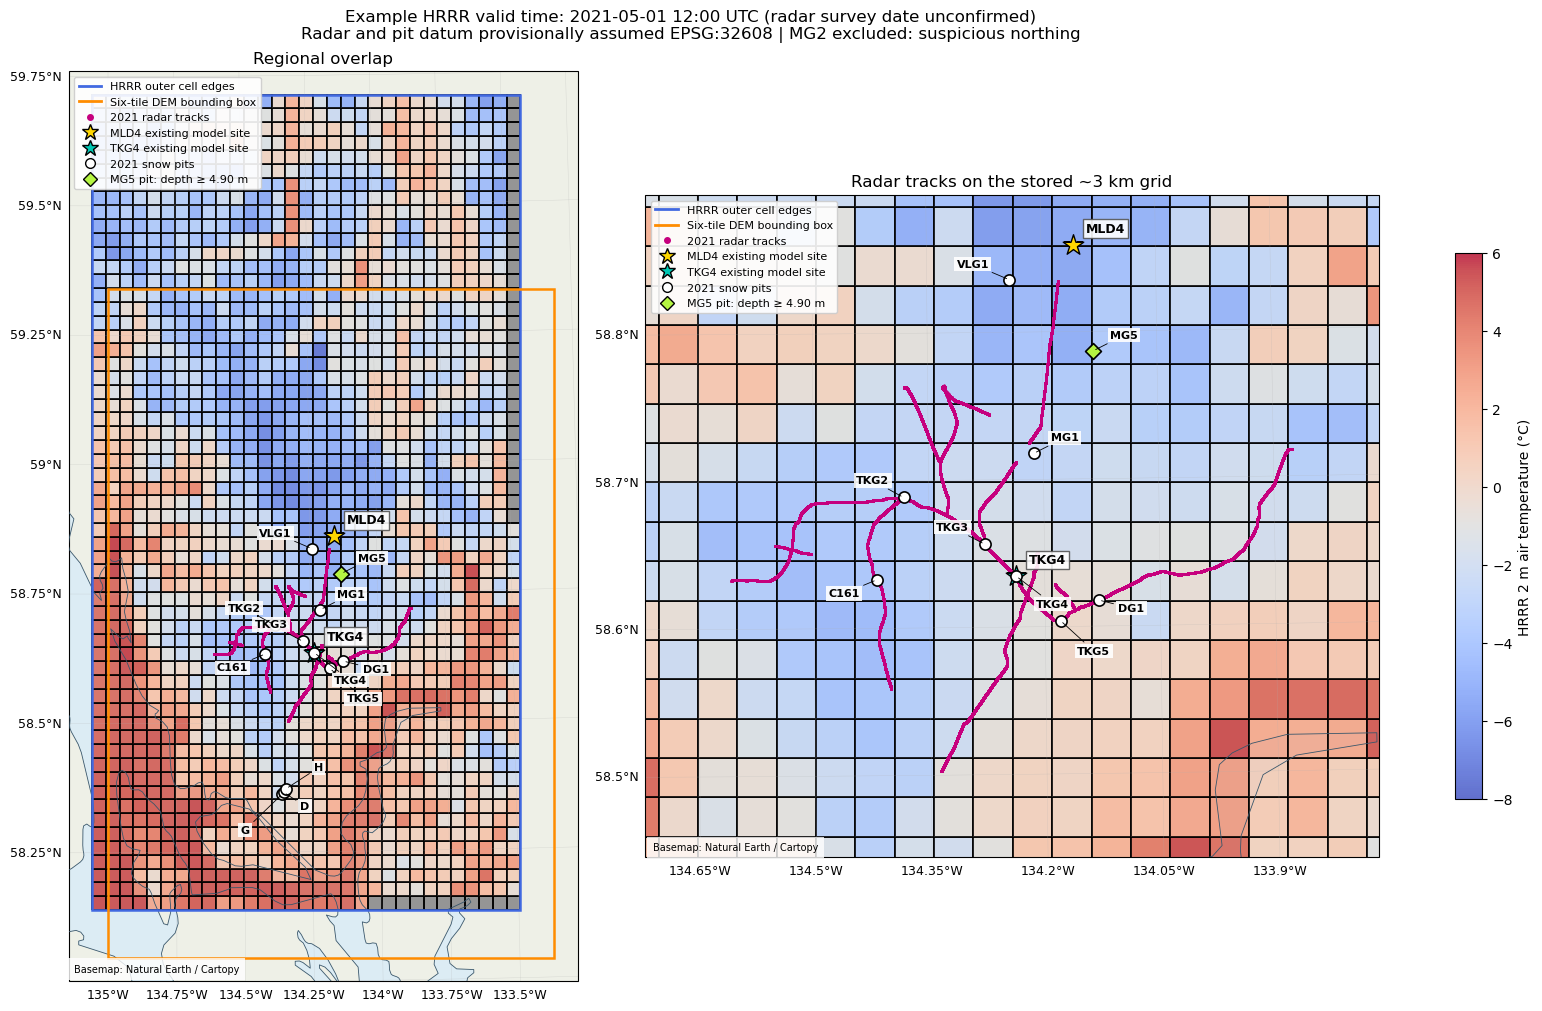

In [6]:
map_crs = ccrs.epsg(grid_crs.to_epsg())
fig, axes = plt.subplots(1, 2, figsize=(17, 10), subplot_kw={'projection': map_crs}, constrained_layout=True)
regional_bounds = (min(hrrr_bounds[0], dem_bounds[0]) - 5000,
                   min(hrrr_bounds[1], dem_bounds[1]) - 5000,
                   max(hrrr_bounds[2], dem_bounds[2]) + 5000,
                   max(hrrr_bounds[3], dem_bounds[3]) + 5000)
zoom_bounds = (gx.min() - 6500, gy.min() - 6500, gx.max() + 6500, gy.max() + 6500)
finite_temp = temp_c[np.isfinite(temp_c)]
if not finite_temp.size:
    raise ValueError('Selected snapshot has no finite temperature.')
vmin, vmax = np.floor(finite_temp.min()), np.ceil(finite_temp.max())
if vmin == vmax:
    vmax = vmin + 1
legend_handles = [Line2D([], [], color='royalblue', linewidth=2, label='HRRR outer cell edges'),
                  Line2D([], [], color='darkorange', linewidth=2, label='Six-tile DEM bounding box'),
                  Line2D([], [], color='#c6007e', marker='o', linestyle='none', markersize=4, label='2021 radar tracks')]
for ax, bounds, title in zip(axes, [regional_bounds, zoom_bounds],
                             ['Regional overlap', 'Radar tracks on the stored ~3 km grid']):
    ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3])
    ax.add_feature(cfeature.OCEAN.with_scale('10m'), facecolor='#dcecf4', zorder=0)
    ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#eef0e7', zorder=0)
    ax.pcolormesh(x_edges, y_edges, np.where(np.isfinite(temp_c), np.nan, 1),
                   transform=map_crs, cmap='Greys', vmin=0, vmax=2, shading='flat', zorder=1)
    mesh = ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(temp_c), transform=map_crs,
                         cmap='coolwarm', vmin=vmin, vmax=vmax, shading='flat', alpha=0.8,
                         edgecolors=(0, 0, 0, 0.22), linewidth=0.2, zorder=2)
    ax.coastlines(resolution='10m', color='#38566b', linewidth=0.6, zorder=3)
    for rectangle, colour in [(hrrr_bounds, 'royalblue'), (dem_bounds, 'darkorange')]:
        left, bottom, right, top = rectangle
        ax.add_patch(Rectangle((left, bottom), right - left, top - bottom, fill=False,
                                edgecolor=colour, linewidth=1.8, transform=map_crs, zorder=4))
    ax.scatter(gx, gy, transform=map_crs, s=0.6, color='#c6007e', rasterized=True, zorder=5)
    grid = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.4)
    grid.top_labels = False; grid.right_labels = False
    grid.xlabel_style = {'size': 9}; grid.ylabel_style = {'size': 9}
    ax.set_title(title)
    add_reference_sites(ax)
    add_snow_pits(ax, bounds, regional=(ax is axes[0]))
    # Reapply fixed bounds so added observations cannot change framing.
    ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3])
    ax.legend(handles=legend_handles + reference_site_handles + pit_handles, loc='upper left', fontsize=8, framealpha=0.9)
    ax.text(0.01, 0.01, 'Basemap: Natural Earth / Cartopy', transform=ax.transAxes,
             fontsize=7, zorder=6, bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
fig.colorbar(mesh, ax=list(axes), shrink=0.6, label='HRRR 2 m air temperature (°C)')
fig.suptitle(f'Example HRRR valid time: {actual_time:%Y-%m-%d %H:%M} UTC (radar survey date unconfirmed)\n'
             f'Radar and pit datum provisionally assumed EPSG:{RADAR_EPSG} | MG2 excluded: suspicious northing', fontsize=12)
if SAVE_OUTPUTS:
    fig.savefig(FIGURE_DIR / 'radar_hrrrak_dem_coverage_2021.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Candidate grid cells for point-model design

- Summarize **each stored UTM grid cell intersected by radar points**, with row counts, profiles, and DEM elevation ranges.
- Report the distance from each radar point to its assigned cell centre.
- Compare median radar-location DEM elevation with HRRR orography to identify scale differences; this is **not an automatic lapse-rate correction**.
- A cell intersected by tracks is a candidate grouping, not necessarily a single representative modeling site. Elevation, glacier setting, and survey timing still matter.
- Keep duplicates and repeated locations visible: counts are source rows, not independent observations or sampled area.

55 stored grid cells intersect the radar tracks.


,grid_row_south_to_north,grid_col_west_to_east,radar_rows,profiles,cell_centre_x,cell_centre_y,dem_elevation_min_m,dem_elevation_median_m,dem_elevation_max_m,hrrr_orography_m,example_temperature_C,max_distance_to_cell_centre_m,median_dem_minus_hrrr_orography_m,example_time_UTC
17,18,16,5275,2,545522.712320,6.499251e+06,1069.372803,1094.975342,1120.766602,1055.800987,-0.779028,1604.080633,39.174355,2021-05-01 12:00:00
24,19,10,4999,2,527684.750681,6.502224e+06,1507.284912,1546.673706,1567.579102,1589.769737,-4.091528,1612.854325,-43.096031,2021-05-01 12:00:00
36,20,15,4621,1,542549.718714,6.505197e+06,1232.911377,1295.382935,1324.349487,1246.113487,-1.779028,1828.587791,49.269448,2021-05-01 12:00:00
33,20,12,4306,2,533630.737894,6.505197e+06,1348.362427,1372.398682,1420.223511,1382.800987,-3.404028,1519.360581,-10.402305,2021-05-01 12:00:00
9,17,16,4057,2,545522.712320,6.496278e+06,1017.534912,1049.957031,1082.583374,1017.707237,-0.904028,1639.008476,32.249794,2021-05-01 12:00:00
27,19,15,4004,2,542549.718714,6.502224e+06,1144.764526,1205.412964,1232.911377,1156.207237,-1.404028,1827.783210,49.205727,2021-05-01 12:00:00
10,17,17,3720,2,548495.705927,6.496278e+06,977.538147,983.510864,1017.534912,939.957237,-0.091528,1971.639612,43.553627,2021-05-01 12:00:00
1,14,14,3606,1,539576.725107,6.487359e+06,1216.822266,1245.794067,1265.578247,1253.488487,-2.154028,1895.749969,-7.694419,2021-05-01 12:00:00
6,16,15,3546,1,542549.718714,6.493305e+06,1067.165405,1100.753418,1138.206421,1107.332237,-1.404028,1837.889962,-6.578819,2021-05-01 12:00:00
35,20,14,3492,2,539576.725107,6.505197e+06,1248.098633,1271.007629,1302.358398,1238.957237,-2.029028,1709.965659,32.050393,2021-05-01 12:00:00


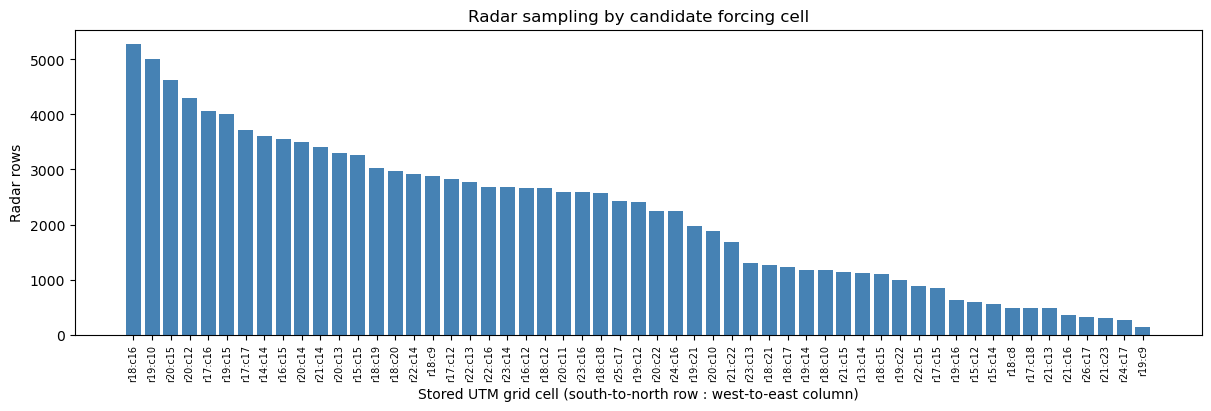

In [7]:
assigned = points.loc[inside_hrrr].copy()
if assigned.empty:
    raise ValueError('No radar points overlap the HRRR grid.')
cc = assigned.grid_col_west_to_east.to_numpy(dtype=int)
rr = assigned.grid_row_south_to_north.to_numpy(dtype=int)
assigned['cell_centre_x'] = x[cc]
assigned['cell_centre_y'] = y[rr]
assigned['distance_to_cell_centre_m'] = np.hypot(assigned.grid_x - x[cc], assigned.grid_y - y[rr])
candidates = assigned.groupby(['grid_row_south_to_north', 'grid_col_west_to_east']).agg(
    radar_rows=('profile', 'size'), profiles=('profile', 'nunique'),
    cell_centre_x=('cell_centre_x', 'first'), cell_centre_y=('cell_centre_y', 'first'),
    dem_elevation_min_m=('dem_elevation_m', 'min'), dem_elevation_median_m=('dem_elevation_m', 'median'),
    dem_elevation_max_m=('dem_elevation_m', 'max'), hrrr_orography_m=('hrrr_orography_m', 'first'),
    example_temperature_C=('hrrr_temperature_C', 'first'),
    max_distance_to_cell_centre_m=('distance_to_cell_centre_m', 'max')).reset_index()
candidates['median_dem_minus_hrrr_orography_m'] = candidates.dem_elevation_median_m - candidates.hrrr_orography_m
candidates['example_time_UTC'] = str(actual_time)
candidates = candidates.sort_values('radar_rows', ascending=False)
assert candidates.radar_rows.sum() == int(inside_hrrr.sum())
print(f'{len(candidates):,} stored grid cells intersect the radar tracks.')
display(candidates)
if SAVE_OUTPUTS:
    candidates.to_csv(DATA_DIR / 'radar_hrrrak_candidate_cells.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
labels = [f'r{r}:c{c}' for r, c in candidates[['grid_row_south_to_north', 'grid_col_west_to_east']].itertuples(index=False, name=None)]
ax.bar(np.arange(len(candidates)), candidates.radar_rows, color='steelblue')
ax.set_xticks(np.arange(len(candidates)), labels, rotation=90, fontsize=7)
ax.set(xlabel='Stored UTM grid cell (south-to-north row : west-to-east column)',
       ylabel='Radar rows', title='Radar sampling by candidate forcing cell')
if SAVE_OUTPUTS:
    fig.savefig(FIGURE_DIR / 'radar_hrrrak_candidate_cell_counts.png', dpi=180)
plt.show()

## 6. Select one radar point per forcing cell

### Maximum number of candidate runs

Under a **one-run-per-stored-grid-cell** design, the upper limit is the number of cells intersected by radar tracks. More points within the same cell would reuse the same cell forcing; they are useful observations for evaluating that run, not additional forcing locations.

We distinguish:

- **Intersected cells:** the geometric upper limit, currently 55 stored UTM cells.
- **Eligible cells:** cells containing at least one radar row that passes the checks below.
- **Selected sites:** one actual eligible radar row per eligible cell, rather than a synthetic point between tracks.

### Selection rule

1. Retain radar rows with finite, non-negative depth, travel time, and SWE, a valid DEM elevation, and finite HRRR temperature/orography at the example time.
2. Within each eligible cell, select the radar point **nearest the cell centre**.
3. Break equal-distance ties using the original CSV row number for reproducibility.
4. Assign a site ID from the sorted grid row/column. Map numbers are short labels linked to those IDs in the table.

**Why this rule?** It places each candidate on an actual radar observation while keeping it as close as possible to its forcing cell centre. It does not optimize terrain representativeness. The selected-point DEM elevation and its difference from HRRR orography remain visible for review.

> **Eligibility is preliminary:** it excludes obvious missing/negative measurements but is not a complete radar quality assessment. Counts retain repeated observations. Full forcing availability, acquisition dates, and radar datum still need confirmation. Stored UTM cells are not verified unique native HRRR cells, so this is a candidate-run upper limit on the downloaded grid.

In [8]:
cell_keys = ['grid_row_south_to_north', 'grid_col_west_to_east']
measurement_columns = ['twtt1', 'aa_avg_depth_m', 'aa_swe_avg_m']
measurement_ok = np.isfinite(assigned[measurement_columns]).all(axis=1) & (assigned[measurement_columns] >= 0).all(axis=1)
site_eligible = (measurement_ok & assigned.valid_dem_elevation
                 & assigned.valid_hrrr_temperature & assigned.valid_hrrr_orography)
assigned['site_selection_eligible'] = site_eligible
eligible = assigned.loc[site_eligible].copy()
if eligible.empty:
    raise ValueError('No radar points pass the preliminary site-selection criteria.')
selected_sites = (eligible.sort_values(cell_keys + ['distance_to_cell_centre_m', 'source_csv_row_0based'], kind='stable')
                  .drop_duplicates(cell_keys, keep='first').sort_values(cell_keys).copy())
selected_sites['site_id'] = [f'JIF_R{int(r):02d}_C{int(c):02d}'
                            for r, c in selected_sites[cell_keys].itertuples(index=False, name=None)]
selected_sites['map_number'] = np.arange(1, len(selected_sites) + 1)
selected_sites['dem_minus_hrrr_orography_m'] = selected_sites.dem_elevation_m - selected_sites.hrrr_orography_m
selected_sites['selection_rule'] = 'Nearest eligible radar row to stored UTM cell centre; ties by CSV row'
selected_sites['selection_status'] = 'Candidate; dates, datum and full forcing availability unverified'

eligibility_by_cell = assigned.groupby(cell_keys).agg(
    radar_rows=('profile', 'size'), eligible_radar_rows=('site_selection_eligible', 'sum')).reset_index()
eligibility_by_cell = eligibility_by_cell.merge(selected_sites[cell_keys + ['site_id', 'map_number']],
                                                on=cell_keys, how='left', validate='one_to_one')
selection_summary = pd.DataFrame({
    'quantity': ['Radar-intersected stored cells (upper limit)', 'Cells with an eligible radar point',
                 'Selected candidate runs', 'Intersected cells without an eligible point',
                 'Radar rows excluded from site selection'],
    'count': [len(candidates), len(selected_sites), len(selected_sites),
              len(candidates) - len(selected_sites), int((~site_eligible).sum())]})
display(selection_summary)
site_columns = ['map_number', 'site_id', 'source_csv_row_0based', 'profile', *cell_keys,
                'grid_x', 'grid_y', 'cell_centre_x', 'cell_centre_y', 'distance_to_cell_centre_m',
                'dem_elevation_m', 'hrrr_orography_m', 'dem_minus_hrrr_orography_m',
                'aa_avg_depth_m', 'aa_swe_avg_m', 'hrrr_example_time_UTC', 'radar_crs_assumption',
                'selection_rule', 'selection_status']
display(selected_sites[site_columns])

# Check the one-site-per-cell design and nearest eligible point rule.
assert not selected_sites.duplicated(cell_keys).any()
assert selected_sites.source_csv_row_0based.is_unique
assert len(selected_sites) == len(eligible.groupby(cell_keys))
expected_minimum = eligible.groupby(cell_keys).distance_to_cell_centre_m.min()
actual_distance = selected_sites.set_index(cell_keys).distance_to_cell_centre_m
assert np.allclose(actual_distance.sort_index(), expected_minimum.sort_index())
assert np.array_equal(np.searchsorted(x_edges, selected_sites.grid_x, side='right') - 1,
                      selected_sites.grid_col_west_to_east.to_numpy(dtype=int))
assert np.array_equal(np.searchsorted(y_edges, selected_sites.grid_y, side='right') - 1,
                      selected_sites.grid_row_south_to_north.to_numpy(dtype=int))
if SAVE_OUTPUTS:
    selected_sites[site_columns].to_csv(DATA_DIR / 'radar_hrrrak_selected_model_sites.csv', index=False)
    eligibility_by_cell.to_csv(DATA_DIR / 'radar_hrrrak_site_eligibility_by_cell.csv', index=False)
    selection_summary.to_csv(DATA_DIR / 'radar_hrrrak_site_selection_summary.csv', index=False)
print(f'Maximum on the stored intersected grid: {len(candidates)} candidate runs; '
      f'{len(selected_sites)} cells have a selected eligible radar point.')

,quantity,count
0,Radar-intersected stored cells (upper limit),55
1,Cells with an eligible radar point,55
2,Selected candidate runs,55
3,Intersected cells without an eligible point,0
4,Radar rows excluded from site selection,7417


,map_number,site_id,source_csv_row_0based,profile,grid_row_south_to_north,grid_col_west_to_east,grid_x,grid_y,cell_centre_x,cell_centre_y,distance_to_cell_centre_m,dem_elevation_m,hrrr_orography_m,dem_minus_hrrr_orography_m,aa_avg_depth_m,aa_swe_avg_m,hrrr_example_time_UTC,radar_crs_assumption,selection_rule,selection_status
39651,1,JIF_R13_C14,39651,SWB,13,14,538628.4425,6484862.622,539576.725107,6.484386e+06,1061.307645,1215.598389,995.207237,220.391152,3.530162,1.939220,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
36958,2,JIF_R14_C14,36958,SWB,14,14,539821.4819,6487259.134,539576.725107,6.487359e+06,264.357830,1250.490845,1253.488487,-2.997642,4.123980,2.279870,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
4382,3,JIF_R15_C12,4382,NWBS,15,12,534846.0377,6491116.846,533630.737894,6.490332e+06,1446.685900,1559.208618,1508.394737,50.813881,8.180002,4.650601,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
34398,4,JIF_R15_C14,34398,SWB,15,14,541052.4507,6489274.691,539576.725107,6.490332e+06,1815.411216,1207.374512,1237.113487,-29.738975,3.751363,2.065860,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
32565,5,JIF_R15_C15,32565,SWB,15,15,542050.6329,6490705.221,542549.718714,6.490332e+06,623.187837,1170.204224,1063.488487,106.715737,3.809624,2.099267,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
6458,6,JIF_R16_C12,6458,NWBS,16,12,534204.8998,6493463.984,533630.737894,6.493305e+06,595.762026,1596.936401,1581.394737,15.541665,6.237594,3.507184,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
28722,7,JIF_R16_C15,28722,SWB,16,15,543464.7829,6493671.347,542549.718714,6.493305e+06,985.667343,1095.786499,1107.332237,-11.545738,3.914383,2.159387,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
8882,8,JIF_R17_C12,8882,NWBS,17,12,534158.6066,6496083.629,533630.737894,6.496278e+06,562.520748,1551.320679,1594.707237,-43.386558,5.028656,2.802642,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
26840,9,JIF_R17_C15,26840,SWB,17,15,543976.2137,6495487.866,542549.718714,6.496278e+06,1630.710426,1055.517334,1097.269737,-41.752403,2.878162,1.567912,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."
17582,10,JIF_R17_C16,17582,Matthes-Taku,17,16,546216.9356,6497071.237,545522.712320,6.496278e+06,1054.112908,1042.137939,1017.707237,24.430703,2.760209,1.501085,2021-05-01 12:00:00,EPSG:32608,Nearest eligible radar row to stored UTM cell ...,"Candidate; dates, datum and full forcing avail..."


Maximum on the stored intersected grid: 55 candidate runs; 55 cells have a selected eligible radar point.


## 7. What would the model locations look like?

- **Left panel:** one numbered candidate site per eligible cell, with all radar tracks for context.
- **Right panel:** open squares mark forcing cell centres; thin connectors lead to the selected radar observations.
- **Point colours on the right:** selected DEM elevation minus HRRR orography. This diagnoses terrain differences without applying a downscaling correction.
- **Thin black cell outlines:** the stored projected HRRR grid. Orange outlines identify cells intersected by radar but lacking an eligible selection, if any.
- **Map labels:** correspond to `map_number` and `site_id` in the exported table.

The selected radar point identifies an observation location for comparison. Extract the forcing series using its **assigned cell centre/index**, not a new interpolated location. Other observations within that cell remain useful for assessing within-cell variability.

For future forcing extraction, select the saved centre coordinates explicitly (for example, `ds.sel(x=cell_centre_x, y=cell_centre_y)`). Table row indices run south-to-north; do not apply them directly with `isel` to the original file, whose y coordinate runs north-to-south.

**Star markers:** gold **MLD4** and turquoise **TKG4** mark the existing model sites in every map panel. They are reference locations and do not alter the 55-cell candidate selection.

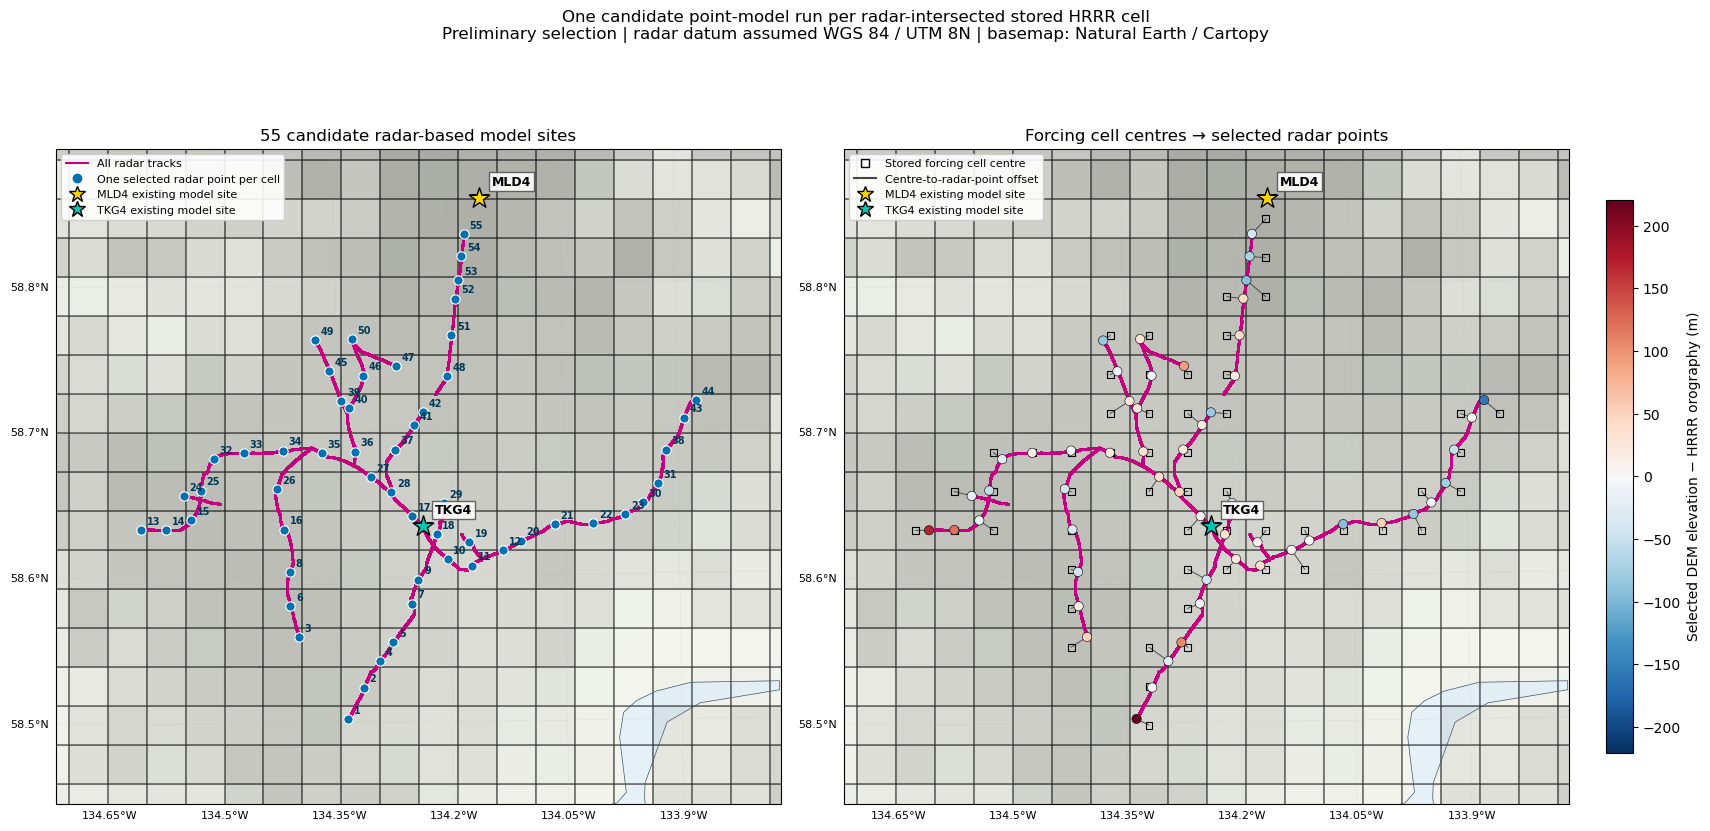

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 9), subplot_kw={'projection': map_crs}, constrained_layout=True)
for ax in axes:
    ax.set_xlim(zoom_bounds[0], zoom_bounds[2]); ax.set_ylim(zoom_bounds[1], zoom_bounds[3])
    ax.add_feature(cfeature.OCEAN.with_scale('10m'), facecolor='#dcecf4', zorder=0)
    ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#eef0e7', zorder=0)
    ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(orography), transform=map_crs,
                   cmap='Greys', alpha=0.3, shading='flat', edgecolors=(0, 0, 0, 0.35), linewidth=0.35, zorder=1)
    ax.coastlines(resolution='10m', color='#38566b', linewidth=0.5, zorder=2)
    ax.scatter(gx, gy, transform=map_crs, color='#c6007e', s=0.5, alpha=0.65, rasterized=True, zorder=3)
    grid = ax.gridlines(draw_labels=True, linewidth=0.25, alpha=0.35)
    grid.top_labels = False; grid.right_labels = False
    grid.xlabel_style = {'size': 8}; grid.ylabel_style = {'size': 8}
    for _, cell in eligibility_by_cell.loc[eligibility_by_cell.site_id.isna()].iterrows():
        r, c = int(cell.grid_row_south_to_north), int(cell.grid_col_west_to_east)
        ax.add_patch(Rectangle((x_edges[c], y_edges[r]), x_edges[c+1] - x_edges[c], y_edges[r+1] - y_edges[r],
                                transform=map_crs, fill=False, edgecolor='darkorange', linewidth=2, zorder=4))
axes[0].scatter(selected_sites.grid_x, selected_sites.grid_y, transform=map_crs,
                 s=45, color='#0072b2', edgecolors='white', linewidths=0.8, zorder=5)
for site in selected_sites.itertuples():
    axes[0].annotate(str(site.map_number), xy=(site.grid_x, site.grid_y),
                     xytext=(4, 4), textcoords='offset points', fontsize=7, color='#003957',
                     fontweight='bold', zorder=6)
    axes[1].plot([site.cell_centre_x, site.grid_x], [site.cell_centre_y, site.grid_y],
                  transform=map_crs, color='#444444', linewidth=0.65, zorder=4)
axes[1].scatter(selected_sites.cell_centre_x, selected_sites.cell_centre_y, transform=map_crs,
                 marker='s', s=25, facecolors='none', edgecolors='black', linewidths=0.8, zorder=5)
elevation_difference = selected_sites.dem_minus_hrrr_orography_m.to_numpy()
limit = max(1.0, np.nanmax(np.abs(elevation_difference)))
markers = axes[1].scatter(selected_sites.grid_x, selected_sites.grid_y, transform=map_crs,
                           c=elevation_difference, cmap='RdBu_r', vmin=-limit, vmax=limit,
                           s=45, edgecolors='black', linewidths=0.4, zorder=6)
fig.colorbar(markers, ax=axes[1], shrink=0.65, label='Selected DEM elevation − HRRR orography (m)')
for ax in axes:
    add_reference_sites(ax)
axes[0].set_title(f'{len(selected_sites)} candidate radar-based model sites')
axes[1].set_title('Forcing cell centres → selected radar points')
axes[0].legend(handles=[Line2D([], [], color='#c6007e', label='All radar tracks'),
                        Line2D([], [], marker='o', color='#0072b2', linestyle='none', label='One selected radar point per cell')] + reference_site_handles,
                loc='upper left', fontsize=8, framealpha=0.9)
axes[1].legend(handles=[Line2D([], [], marker='s', markerfacecolor='none', color='black', linestyle='none', label='Stored forcing cell centre'),
                        Line2D([], [], color='#444444', label='Centre-to-radar-point offset')] + reference_site_handles,
                loc='upper left', fontsize=8, framealpha=0.9)
fig.suptitle('One candidate point-model run per radar-intersected stored HRRR cell\n'
             'Preliminary selection | radar datum assumed WGS 84 / UTM 8N | basemap: Natural Earth / Cartopy', fontsize=12)
if SAVE_OUTPUTS:
    fig.savefig(FIGURE_DIR / 'radar_hrrrak_selected_model_sites.png', dpi=180, bbox_inches='tight')
plt.show()

## Next steps toward point modeling

- [ ] **Confirm survey dates:** replace the illustrative timestamp with actual radar acquisition dates or time windows.
- [ ] **Confirm radar datum:** verify alignment before selecting precise point locations.
- [ ] **Review selected candidate sites:** inspect the nearest-centre radar selections against within-cell elevation range, profiles, and glacier setting; approve or revise them before creating run configurations.
- [ ] **Trace the original HRRR grid:** determine how projected cells relate to native forcing locations before extracting new model input series.
- [ ] **Check full forcing availability:** this notebook checks temperature and orography at one time; audit all required variables over the simulation period next.
- [ ] **Choose terrain adjustments:** evaluate elevation and meteorological corrections explicitly if terrain downscaling is needed.
- [ ] **Plan model validation:** match observation timing and model snow variables before computing errors. HRRR snow fields, point-model outputs, and radar SWE are distinct datasets.

**Outputs:** maps in `radar/figures/`; overlap tables and candidate-cell assignments in `radar/data/`. Both are ignored by Git. The executed notebook embeds the figures and summaries. Original datasets are unchanged.

**Candidate-site exports:** `radar_hrrrak_selected_model_sites.csv`, per-cell eligibility counts, and a selection summary in `radar/data/`. These are exploratory outputs, not executable model configurations.